In [1]:
import sys, time
sys.path.append("../src")
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from donnees import charger_raca, nettoyer_raca, reechantillonner_raca
from evaluation import scores_regression
from sequences import (fenetres, entrainer_reseau, predire,
                       ReseauLSTM, ReseauGRU, ReseauCNNLSTM, ReseauLSTMCNN)

serie = reechantillonner_raca(nettoyer_raca(charger_raca()))
dl = serie[serie["application"] == "Download"].copy()
dl["debit"] = dl["DL_bitrate"] / 1000
traces = sorted(dl["trace"].unique())
np.random.default_rng(0).shuffle(traces)
groupes = {"entr": traces[:14], "val": traces[14:17], "test": traces[17:]}
VARIABLES = ["debit", "RSRP", "RSRQ", "SNR", "CQI"]
entr_df = dl[dl["trace"].isin(groupes["entr"])]
moy, ect = entr_df[VARIABLES].mean(), entr_df[VARIABLES].std()

MODELES = {"lstm": ReseauLSTM, "gru": ReseauGRU,
           "cnn_lstm": ReseauCNNLSTM, "lstm_cnn": ReseauLSTMCNN}
for nom, Classe in MODELES.items():
    print(nom, sum(p.numel() for p in Classe(6).parameters()), "paramètres")

lstm 5153 paramètres
gru 3873 paramètres
cnn_lstm 9089 paramètres
lstm_cnn 8257 paramètres


42 époques, meilleure à l'époque 34, 62 s
52 époques, meilleure à l'époque 44, 95 s
46 époques, meilleure à l'époque 38, 65 s
28 époques, meilleure à l'époque 20, 42 s
 horizon   modele  duree_s    MAE   RMSE    R2
       1     lstm       72 15.310 30.499 0.809
       1      gru       95 15.475 30.184 0.812
       1 cnn_lstm       65 15.624 30.196 0.812
       1 lstm_cnn       42 15.307 30.546 0.808


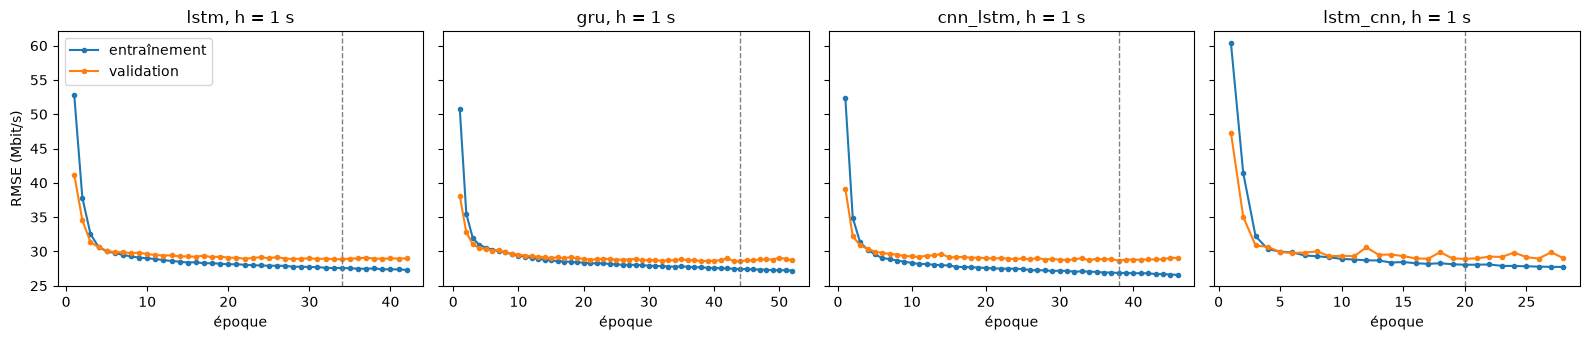

In [2]:
def experience(h):
    D = {nom: fenetres(dl[dl["trace"].isin(liste)], VARIABLES, moy, ect, W=10, h=h)
         for nom, liste in groupes.items()}
    Xe, ye, _, _ = D["entr"]
    Xv, yv, _, _ = D["val"]
    Xt, yt, evt, _ = D["test"]
    lignes, historiques = [], {}
    for nom, Classe in MODELES.items():
        torch.manual_seed(0)
        debut = time.time()
        modele, historiques[nom] = entrainer_reseau(Classe(Xe.shape[2]), Xe, ye, Xv, yv)
        lignes.append({"horizon": h, "modele": nom, "duree_s": round(time.time() - debut),
                       **scores_regression(yt[evt], predire(modele, Xt)[evt])})
    return lignes, historiques


def tracer_courbes(historiques, h):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=True)
    for ax, (nom, hist) in zip(axes, historiques.items()):
        hi = pd.DataFrame(hist)
        ax.plot(hi["epoque"], np.sqrt(hi["perte_entr"]) * 100, marker="o", ms=3, label="entraînement")
        ax.plot(hi["epoque"], np.sqrt(hi["perte_val"]) * 100, marker="o", ms=3, label="validation")
        ax.axvline(hi["perte_val"].idxmin() + 1, color="grey", ls="--", lw=1)
        ax.set_title(f"{nom}, h = {h} s"); ax.set_xlabel("époque")
    axes[0].set_ylabel("RMSE (Mbit/s)"); axes[0].legend()
    fig.tight_layout()
    fig.savefig(f"../results/figures/raca_courbes_reseaux_h{h}.png", dpi=150, bbox_inches="tight")
    plt.show()


lignes_h1, hist_h1 = experience(1)
print(pd.DataFrame(lignes_h1).round(3).to_string(index=False))
tracer_courbes(hist_h1, 1)

16 époques, meilleure à l'époque 8, 25 s
16 époques, meilleure à l'époque 8, 30 s
17 époques, meilleure à l'époque 9, 29 s
16 époques, meilleure à l'époque 8, 22 s
16 époques, meilleure à l'époque 8, 16 s
19 époques, meilleure à l'époque 11, 27 s
14 époques, meilleure à l'époque 6, 24 s
11 époques, meilleure à l'époque 3, 22 s


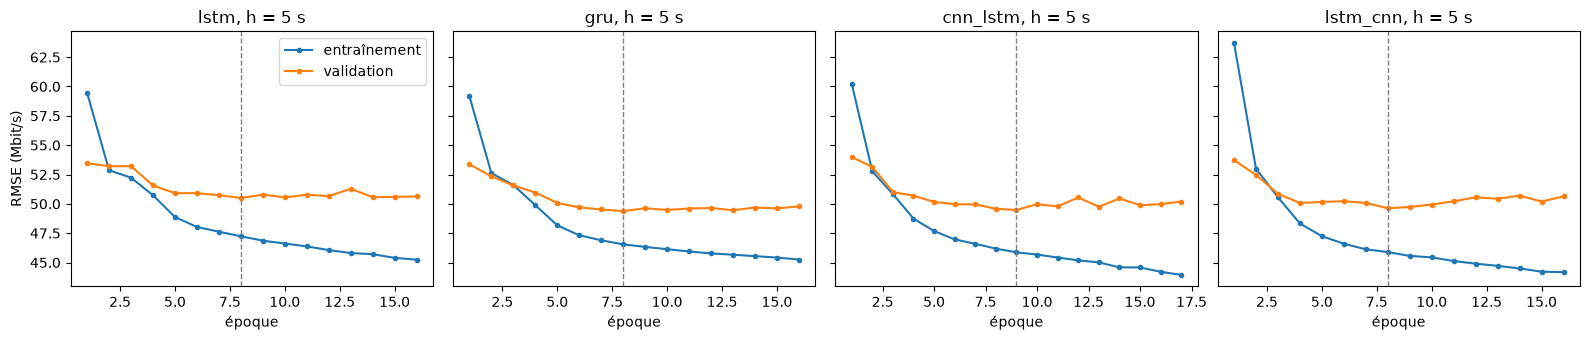

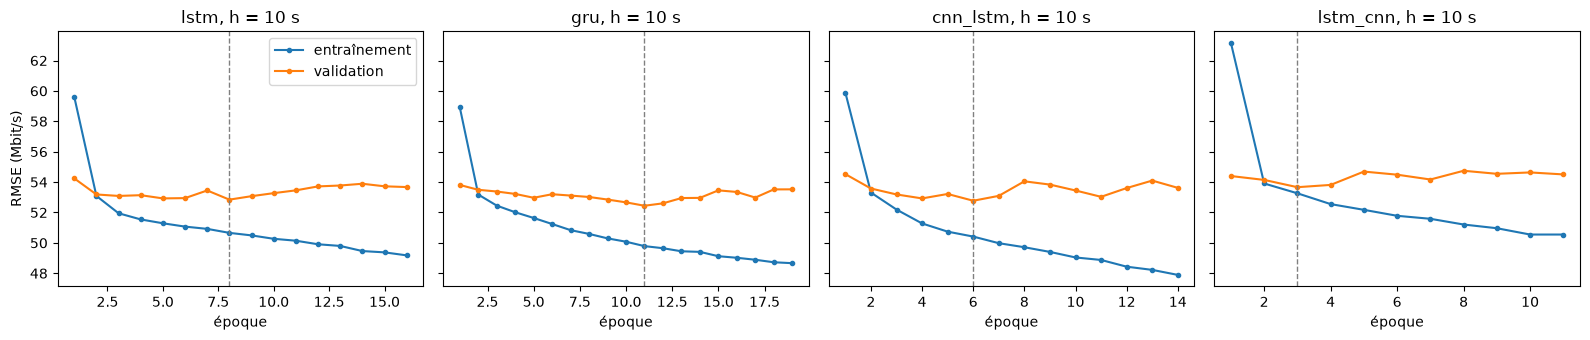

modele   persistance    xgb   lstm    gru  cnn_lstm  lstm_cnn
horizon                                                      
1              0.738  0.784  0.809  0.812     0.812     0.808
5             -0.084  0.477  0.401  0.438     0.438     0.452
10            -0.200  0.352  0.335  0.355     0.335     0.313


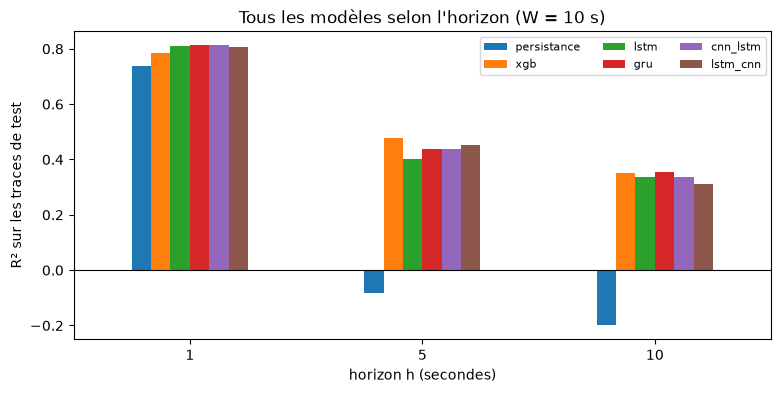

In [3]:
lignes_h5, hist_h5 = experience(5)
lignes_h10, hist_h10 = experience(10)
tracer_courbes(hist_h5, 5)
tracer_courbes(hist_h10, 10)

res = pd.DataFrame(lignes_h1 + lignes_h5 + lignes_h10)
ref = pd.read_csv("../results/tables/raca_horizons_test.csv")
ref = ref[ref["modele"].isin(["persistance", "xgb"])]          # séance 12
tout = pd.concat([ref, res.drop(columns="duree_s")], ignore_index=True).round(3)
tout.to_csv("../results/tables/raca_reseaux_test.csv", index=False)

tab = tout.pivot(index="horizon", columns="modele", values="R2")[
    ["persistance", "xgb", "lstm", "gru", "cnn_lstm", "lstm_cnn"]]
print(tab)
ax = tab.plot.bar(figsize=(9, 4), rot=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("horizon h (secondes)"); ax.set_ylabel("R² sur les traces de test")
ax.set_title("Tous les modèles selon l'horizon (W = 10 s)")
ax.legend(fontsize=8, ncol=3)
ax.figure.savefig("../results/figures/raca_r2_reseaux.png", dpi=150, bbox_inches="tight")
plt.show()